In [1]:
from google.colab import files
import pandas as pd
import io

In [2]:
uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving customer_booking.csv to customer_booking.csv
User uploaded file "customer_booking.csv" with length 3146444 bytes


In [3]:
# Read the uploaded CSV file
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='ISO-8859-1')

# Display the first few rows
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [4]:
# Show information summary of each column including non-null counts and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [6]:
# Check for missing values in each column
display(df.isnull().sum())

,0
num_passengers,0
sales_channel,0
trip_type,0
purchase_lead,0
length_of_stay,0
flight_hour,0
flight_day,0
route,0
booking_origin,0
wants_extra_baggage,0


In [5]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Show duplicate rows if they exist
if duplicate_count > 0:
    display(df[df.duplicated()].head())

Number of duplicate rows: 719


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
196,5,Internet,RoundTrip,206,17,13,Sun,AKLKUL,Malaysia,1,0,0,8.83,0
316,5,Internet,RoundTrip,206,17,13,Sun,AKLKUL,Malaysia,1,0,0,8.83,0
384,5,Internet,RoundTrip,206,17,13,Sun,AKLKUL,Malaysia,1,0,0,8.83,0
456,1,Internet,RoundTrip,30,85,15,Fri,AKLKUL,Malaysia,1,0,0,8.83,1
513,3,Internet,RoundTrip,109,20,4,Tue,AKLKUL,Singapore,1,0,1,8.83,0


In [7]:
# Remove duplicate rows
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
new_rows = df.shape[0]

print(f"Removed {initial_rows - new_rows} duplicate rows.")
print(f"New dataset shape: {df.shape[0]} rows and {df.shape[1]} columns.")

Removed 719 duplicate rows.
New dataset shape: 49281 rows and 14 columns.


Class Counts:
booking_complete
0    41890
1     7391
Name: count, dtype: int64

Class Percentages:
booking_complete
0    85.002334
1    14.997666
Name: proportion, dtype: float64


/tmp/ipykernel_4138/1375117033.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='booking_complete', data=df, palette='viridis')


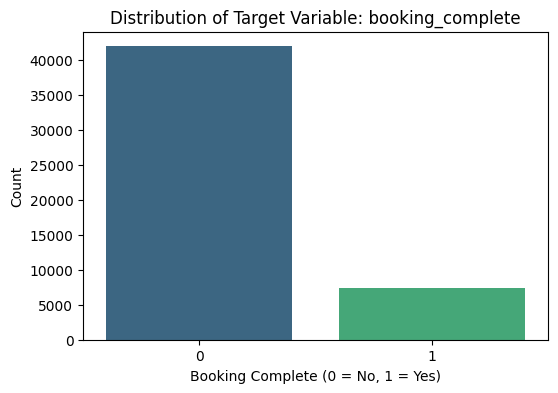

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each class
booking_counts = df['booking_complete'].value_counts()
booking_percentages = df['booking_complete'].value_counts(normalize=True) * 100

print("Class Counts:")
print(booking_counts)
print("\nClass Percentages:")
print(booking_percentages)

# Visualize the distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='booking_complete', data=df, palette='viridis')
plt.title('Distribution of Target Variable: booking_complete')
plt.xlabel('Booking Complete (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

In [9]:
# Show summary statistics for numerical columns
display(df.describe())

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,49281.000000,49281.000000,49281.000000,49281.000000,49281.000000,49281.000000,49281.000000,49281.000000,49281.000000
mean,1.590187,84.723281,23.053976,9.070676,0.668229,0.295631,0.426635,7.279974,0.149977
std,1.016538,90.410229,33.832149,5.413099,0.470854,0.456331,0.494593,1.496390,0.357052
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.000000,5.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.000000,9.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.000000,13.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.000000,23.000000,1.000000,1.000000,1.000000,9.500000,1.000000


In [10]:
import pandas as pd

categorical_cols = ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']

for col in categorical_cols:
    print(f"=== Completion Rate by {col} ===")
    # Group by the category and calculate the mean of booking_complete (which represents completion rate)
    completion_rate = df.groupby(col)['booking_complete'].agg(['count', 'mean']).rename(columns={'mean': 'completion_rate'})
    completion_rate['completion_rate'] = (completion_rate['completion_rate'] * 100).round(2)

    # Sort by completion rate descending
    completion_rate = completion_rate.sort_values(by='completion_rate', ascending=False)

    # For columns with many unique values like route and booking_origin, show top and bottom
    if completion_rate.shape[0] > 10:
        print("Top 5:")
        display(completion_rate.head(5))
        print("Bottom 5:")
        display(completion_rate.tail(5))
    else:
        display(completion_rate)
    print("\n" + "="*40 + "\n")

=== Completion Rate by sales_channel ===


,count,completion_rate
sales_channel,,
Internet,43917,15.49
Mobile,5364,10.98




=== Completion Rate by trip_type ===


,count,completion_rate
trip_type,,
RoundTrip,48779,15.10
OneWay,386,5.18
CircleTrip,116,4.31




=== Completion Rate by flight_day ===


,count,completion_rate
flight_day,,
Wed,7562,16.27
Thu,7323,15.14
Mon,7988,14.95
Sat,5723,14.94
Tue,7558,14.77
Fri,6685,14.60
Sun,6442,14.14


... (4 outputs left out)



=== Completion Rate by booking_origin ===
Top 5:


,count,completion_rate
booking_origin,,
Iraq,1,100.00
Vanuatu,1,100.00
Seychelles,1,100.00
Pakistan,1,100.00
Kazakhstan,3,66.67


Bottom 5:


,count,completion_rate
booking_origin,,
Svalbard & Jan Mayen,1,0.0
Tonga,1,0.0
Timor-Leste,2,0.0
Ukraine,5,0.0
Tunisia,2,0.0


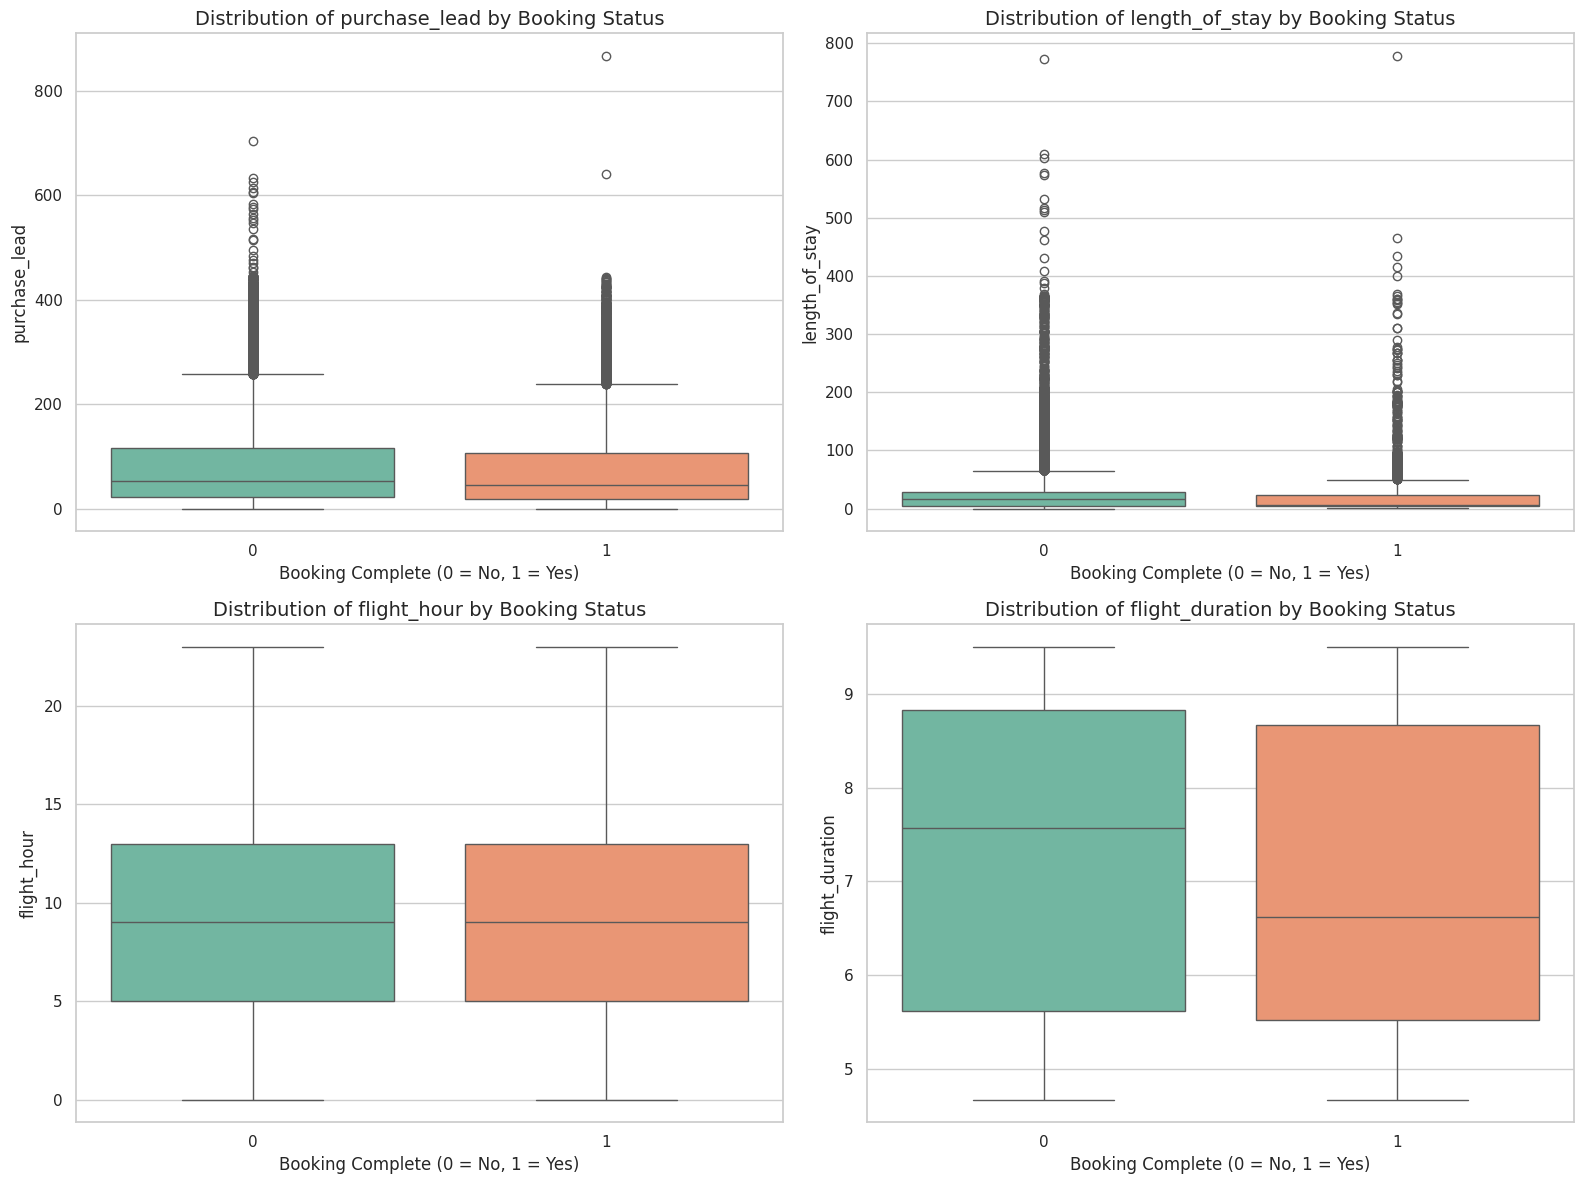

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Define the numerical columns we want to compare
features_to_plot = ['purchase_lead', 'length_of_stay', 'flight_hour', 'flight_duration']

# Create a multi-plot figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    # We will use boxplots to clearly see outliers, medians, and distribution spreads between the two classes
    sns.boxplot(
        x='booking_complete',
        y=col,
        data=df,
        ax=axes[i],
        palette='Set2',
        hue='booking_complete',
        legend=False
    )
    axes[i].set_title(f'Distribution of {col} by Booking Status', fontsize=14)
    axes[i].set_xlabel('Booking Complete (0 = No, 1 = Yes)', fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_4138/3172107022.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(
/tmp/ipykernel_4138/3172107022.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(
/tmp/ipykernel_4138/3172107022.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(
/tmp/ipykernel_4138/3172107022.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(


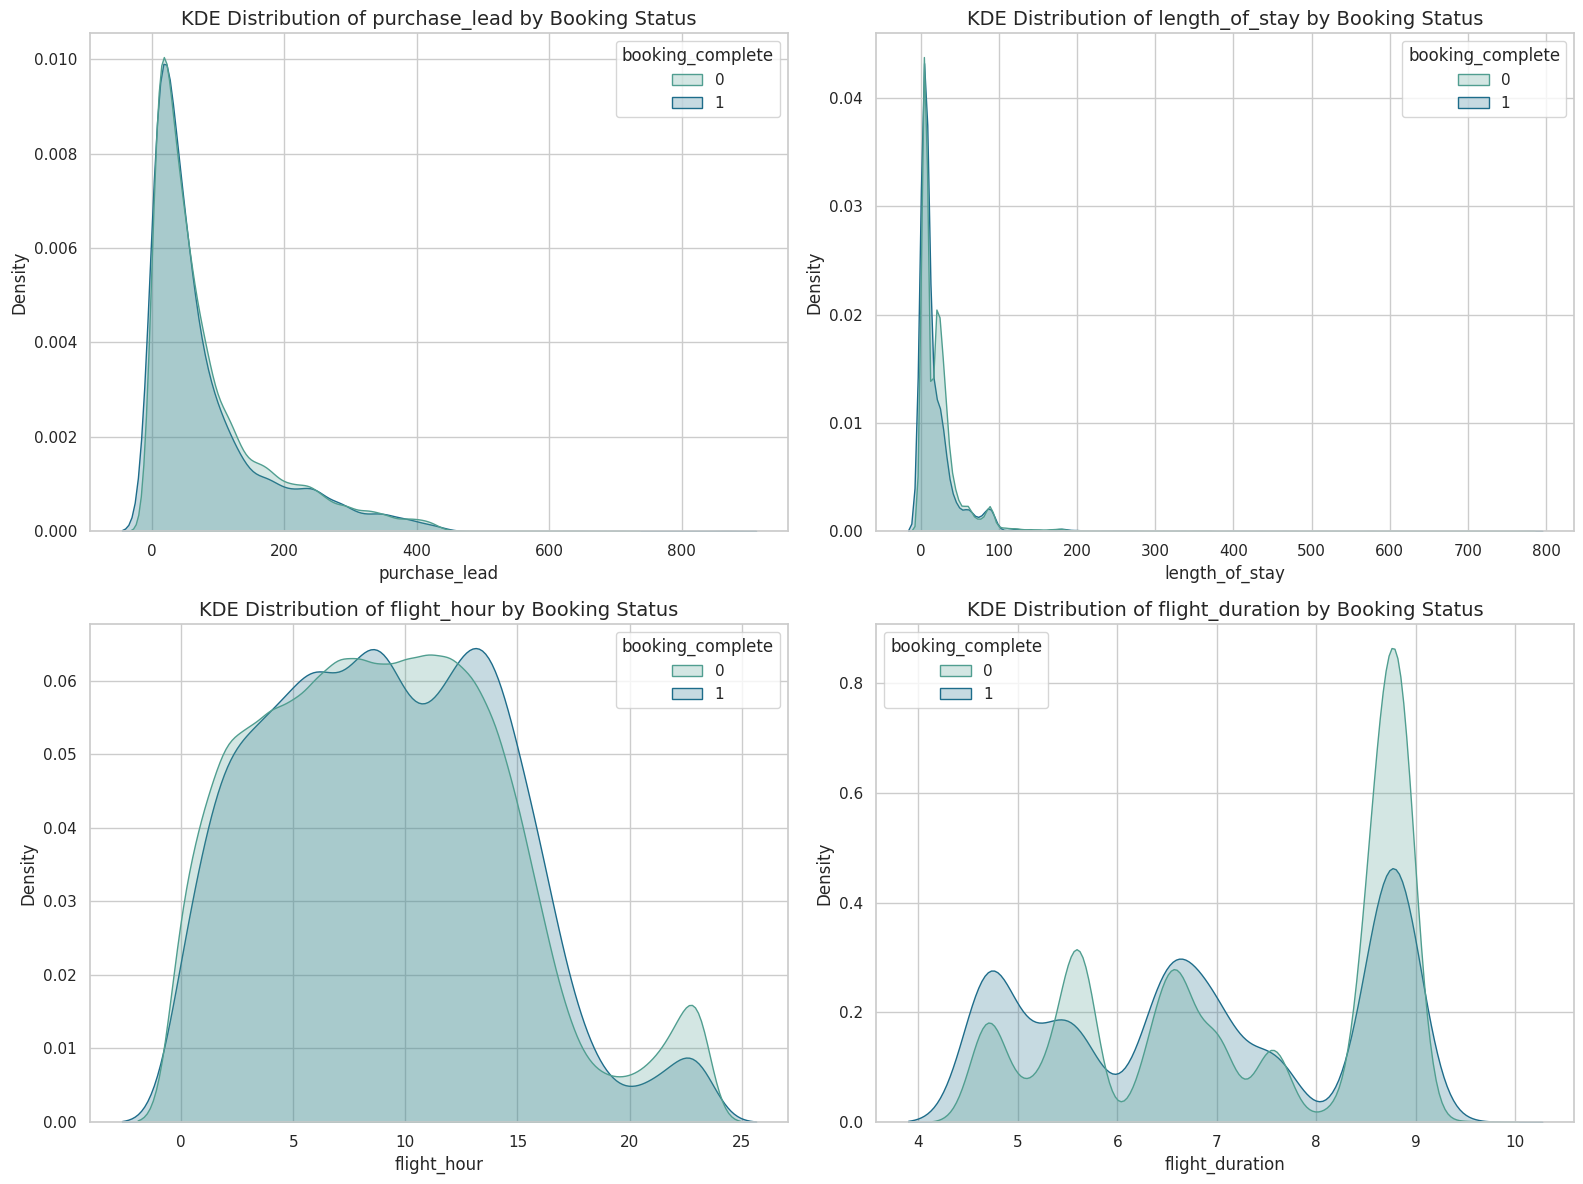

In [12]:
# Let's also look at the KDE (Kernel Density Estimate) plots to see the exact shape of overlapping distributions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.kdeplot(
        data=df,
        x=col,
        hue='booking_complete',
        common_norm=False,
        shade=True,
        palette='crest',
        ax=axes[i]
    )
    axes[i].set_title(f'KDE Distribution of {col} by Booking Status', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Density', fontsize=12)

plt.tight_layout()
plt.show()

=== Conversion rates for wants_extra_baggage ===
booking_complete         0      1
wants_extra_baggage              
0                    88.47  11.53
1                    83.28  16.72


=== Conversion rates for wants_preferred_seat ===
booking_complete          0      1
wants_preferred_seat              
0                     86.16  13.84
1                     82.24  17.76


=== Conversion rates for wants_in_flight_meals ===
booking_complete           0      1
wants_in_flight_meals              
0                      85.82  14.18
1                      83.91  16.09




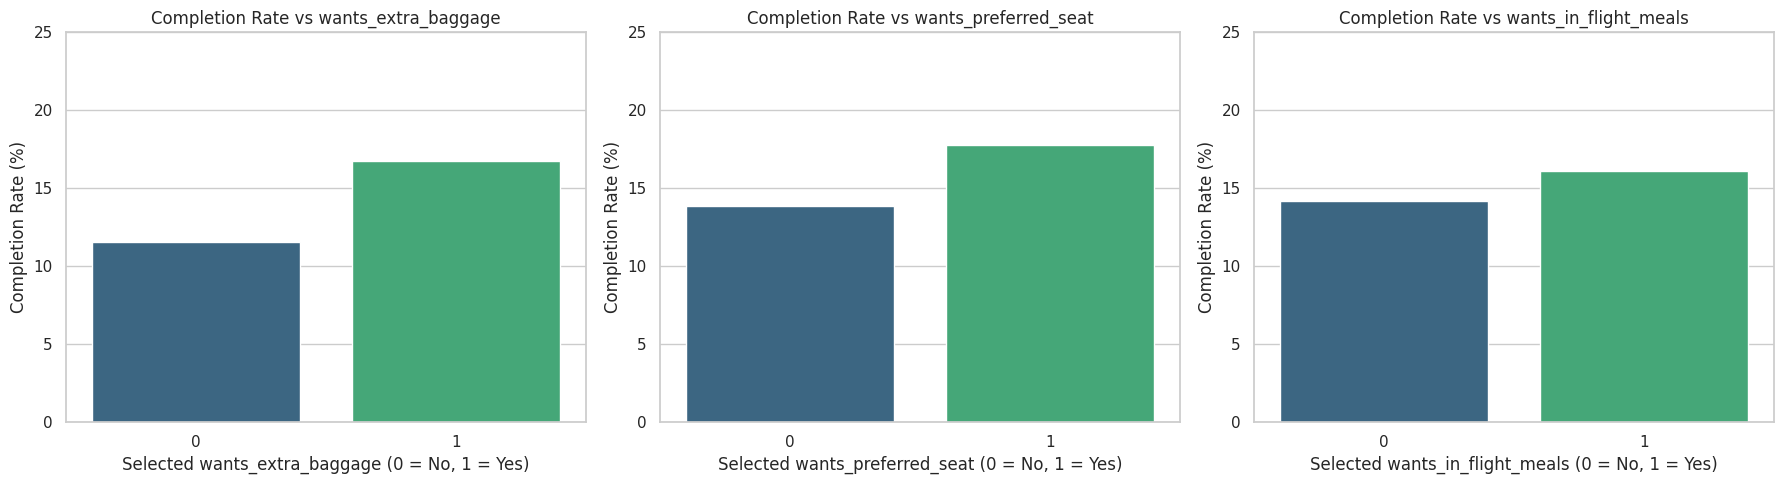

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the add-on columns
addon_cols = ['wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(addon_cols):
    # Calculate rates
    rate_df = df.groupby(col)['booking_complete'].value_counts(normalize=True).unstack() * 100
    print(f"=== Conversion rates for {col} ===")
    print(rate_df.round(2))
    print("\n")

    # Plot completion rate (booking_complete == 1) for each choice
    completion_by_choice = df.groupby(col)['booking_complete'].mean() * 100
    sns.barplot(
        x=completion_by_choice.index,
        y=completion_by_choice.values,
        ax=axes[i],
        palette='viridis',
        hue=completion_by_choice.index,
        legend=False
    )
    axes[i].set_title(f'Completion Rate vs {col}')
    axes[i].set_xlabel(f'Selected {col} (0 = No, 1 = Yes)')
    axes[i].set_ylabel('Completion Rate (%)')
    axes[i].set_ylim(0, 25)

plt.tight_layout()
plt.show()

=== Pearson Correlation Matrix ===


,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
num_passengers,1.000,0.215,-0.115,0.016,0.121,0.030,0.022,-0.062,0.024
purchase_lead,0.215,1.000,-0.077,0.035,-0.022,-0.004,-0.023,0.068,-0.022
length_of_stay,-0.115,-0.077,1.000,-0.026,0.178,0.031,0.099,0.140,-0.042
flight_hour,0.016,0.035,-0.026,1.000,-0.011,0.012,0.012,-0.003,0.007
wants_extra_baggage,0.121,-0.022,0.178,-0.011,1.000,0.208,0.217,0.058,0.068
wants_preferred_seat,0.030,-0.004,0.031,0.012,0.208,1.000,0.315,0.101,0.050
wants_in_flight_meals,0.022,-0.023,0.099,0.012,0.217,0.315,1.000,0.156,0.026
flight_duration,-0.062,0.068,0.140,-0.003,0.058,0.101,0.156,1.000,-0.107
booking_complete,0.024,-0.022,-0.042,0.007,0.068,0.050,0.026,-0.107,1.000


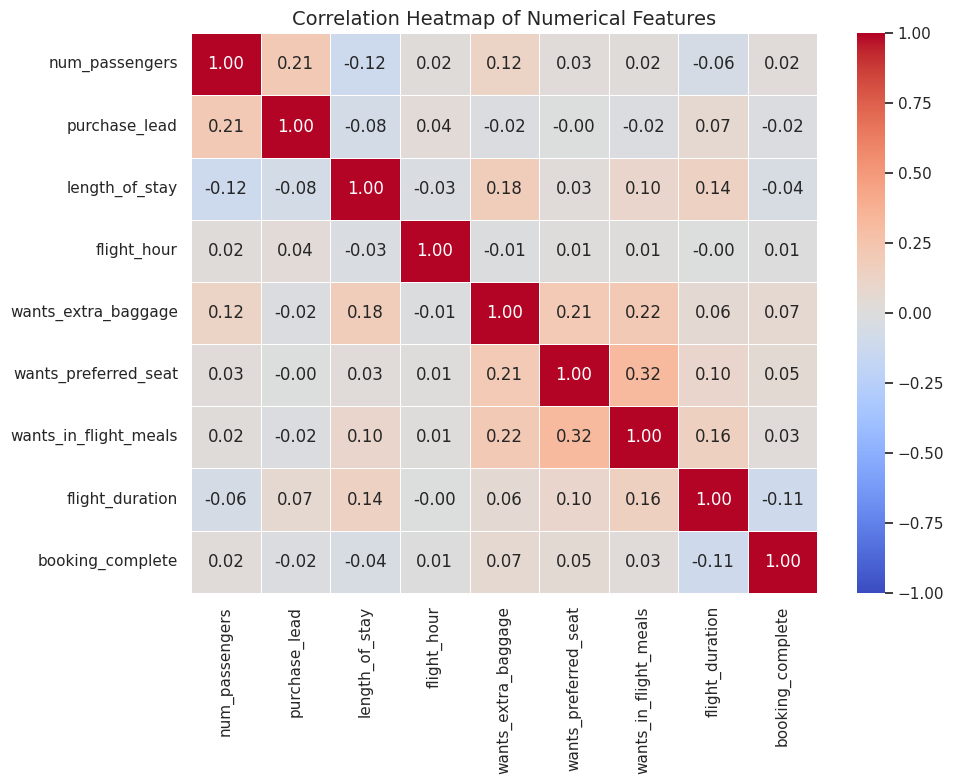

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the numerical columns from the dataset
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Calculate the correlation matrix
corr_matrix = df[numeric_cols].corr()

# Display the correlation matrix values
print("=== Pearson Correlation Matrix ===")
display(corr_matrix.round(3))

# Plot a heatmap of the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd

categorical_cols = ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']

for col in categorical_cols:
    print(f"=== Completion Rate Statistics by {col} ===")

    # Group by category to calculate count and completion rate (mean of booking_complete)
    stats = df.groupby(col)['booking_complete'].agg(['count', 'mean']).rename(columns={'mean': 'completion_rate'})

    # Calculate standard error of the mean: sqrt(p * (1-p) / n)
    p = stats['completion_rate']
    n = stats['count']
    stats['std_error'] = np.sqrt(p * (1 - p) / n)

    # Calculate 95% confidence interval (1.96 * std_error)
    stats['margin_of_error'] = 1.96 * stats['std_error']
    stats['ci_lower'] = np.clip(p - stats['margin_of_error'], 0, 1)
    stats['ci_upper'] = np.clip(p + stats['margin_of_error'], 0, 1)

    # Express rates as percentages
    stats['completion_rate'] = (stats['completion_rate'] * 100).round(2)
    stats['ci_lower'] = (stats['ci_lower'] * 100).round(2)
    stats['ci_upper'] = (stats['ci_upper'] * 100).round(2)

    # Create a nice interval string representation
    stats['95%_confidence_interval'] = stats.apply(lambda row: f"[{row['ci_lower']}%, {row['ci_upper']}%]", axis=1)

    # Keep key columns for presentation
    result = stats[['count', 'completion_rate', '95%_confidence_interval']].sort_values(by='completion_rate', ascending=False)

    if result.shape[0] > 10:
        print("Top 5:")
        display(result.head(5))
        print("Bottom 5:")
        display(result.tail(5))
    else:
        display(result)
    print("\n" + "="*60 + "\n")

=== Completion Rate Statistics by sales_channel ===


,count,completion_rate,95%_confidence_interval
sales_channel,,,
Internet,43917,15.49,"[15.15%, 15.83%]"
Mobile,5364,10.98,"[10.14%, 11.82%]"




=== Completion Rate Statistics by trip_type ===


,count,completion_rate,95%_confidence_interval
trip_type,,,
RoundTrip,48779,15.10,"[14.78%, 15.42%]"
OneWay,386,5.18,"[2.97%, 7.39%]"
CircleTrip,116,4.31,"[0.61%, 8.01%]"




=== Completion Rate Statistics by flight_day ===


,count,completion_rate,95%_confidence_interval
flight_day,,,
Wed,7562,16.27,"[15.43%, 17.1%]"
Thu,7323,15.14,"[14.32%, 15.97%]"
Mon,7988,14.95,"[14.17%, 15.73%]"
Sat,5723,14.94,"[14.02%, 15.86%]"
Tue,7558,14.77,"[13.97%, 15.57%]"
Fri,6685,14.60,"[13.75%, 15.45%]"
Sun,6442,14.14,"[13.29%, 14.99%]"


... (4 outputs left out)



=== Completion Rate Statistics by booking_origin ===
Top 5:


,count,completion_rate,95%_confidence_interval
booking_origin,,,
Iraq,1,100.00,"[100.0%, 100.0%]"
Vanuatu,1,100.00,"[100.0%, 100.0%]"
Seychelles,1,100.00,"[100.0%, 100.0%]"
Pakistan,1,100.00,"[100.0%, 100.0%]"
Kazakhstan,3,66.67,"[13.32%, 100.0%]"


Bottom 5:


,count,completion_rate,95%_confidence_interval
booking_origin,,,
Svalbard & Jan Mayen,1,0.0,"[0.0%, 0.0%]"
Tonga,1,0.0,"[0.0%, 0.0%]"
Timor-Leste,2,0.0,"[0.0%, 0.0%]"
Ukraine,5,0.0,"[0.0%, 0.0%]"
Tunisia,2,0.0,"[0.0%, 0.0%]"


In [16]:
# Split BEFORE learning category frequencies or encoding.
# This keeps information from the held-out test set out of preprocessing.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
import pandas as pd

ml_df = df.copy()
X_raw = ml_df.drop(columns=["booking_complete"])
y = ml_df["booking_complete"].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

categorical_cols = ["sales_channel", "trip_type", "flight_day", "route", "booking_origin"]
num_cols = ["num_passengers", "purchase_lead", "length_of_stay", "flight_hour", "flight_duration"]

# Learn rare-category handling and one-hot categories from training data only.
# min_frequency=50 groups infrequent categories into an infrequent bucket.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False)
except TypeError:  # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse=False)

X_train_cat = encoder.fit_transform(X_train_raw[categorical_cols])
X_test_cat = encoder.transform(X_test_raw[categorical_cols])
encoded_names = encoder.get_feature_names_out(categorical_cols)

X_train = pd.DataFrame(
    np.column_stack([X_train_raw[num_cols].to_numpy(), X_train_cat]),
    columns=num_cols + list(encoded_names),
    index=X_train_raw.index
)
X_test = pd.DataFrame(
    np.column_stack([X_test_raw[num_cols].to_numpy(), X_test_cat]),
    columns=num_cols + list(encoded_names),
    index=X_test_raw.index
)

# Restore numeric dtypes after combining numeric and encoded columns.
X_train[num_cols] = X_train[num_cols].astype(float)
X_test[num_cols] = X_test[num_cols].astype(float)

# Scale numeric columns for Logistic Regression only.
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"Training set: {X_train.shape}; test set: {X_test.shape}")
print(f"Training completion rate: {y_train.mean():.2%}")
print(f"Test completion rate: {y_test.mean():.2%}")


Training set: (39424, 229); test set: (9857, 229)
Training completion rate: 15.00%
Test completion rate: 14.99%


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

# 1. Baseline Logistic Regression
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 2. Random Forest Classifier
rf_model = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train) # Tree-based models don't require scaled numerical variables

# Predictions
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

print("=== Logistic Regression Baseline ===")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}")

print("\n=== Random Forest Classifier ===")
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_probs):.4f}")

=== Logistic Regression Baseline ===
              precision    recall  f1-score   support

           0       0.94      0.68      0.79      8379
           1       0.29      0.74      0.42      1478

    accuracy                           0.69      9857
   macro avg       0.61      0.71      0.60      9857
weighted avg       0.84      0.69      0.73      9857

ROC-AUC: 0.7636

=== Random Forest Classifier ===
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      8379
           1       0.41      0.12      0.18      1478

    accuracy                           0.84      9857
   macro avg       0.63      0.54      0.55      9857
weighted avg       0.79      0.84      0.80      9857

ROC-AUC: 0.7482


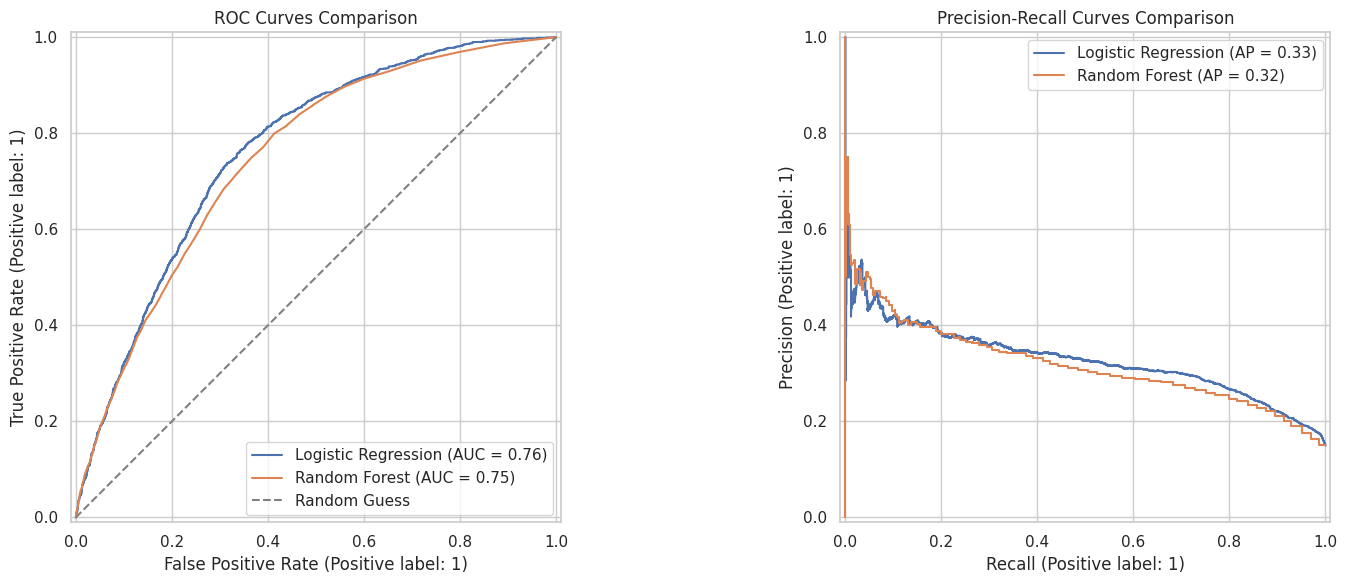

In [18]:
# Plot ROC and Precision-Recall Curves for both models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curve
RocCurveDisplay.from_predictions(y_test, lr_probs, ax=ax1, name='Logistic Regression')
RocCurveDisplay.from_predictions(y_test, rf_probs, ax=ax1, name='Random Forest')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
ax1.set_title('ROC Curves Comparison')
ax1.legend()

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, lr_probs, ax=ax2, name='Logistic Regression')
PrecisionRecallDisplay.from_predictions(y_test, rf_probs, ax=ax2, name='Random Forest')
ax2.set_title('Precision-Recall Curves Comparison')
ax2.legend()

plt.tight_layout()
plt.show()

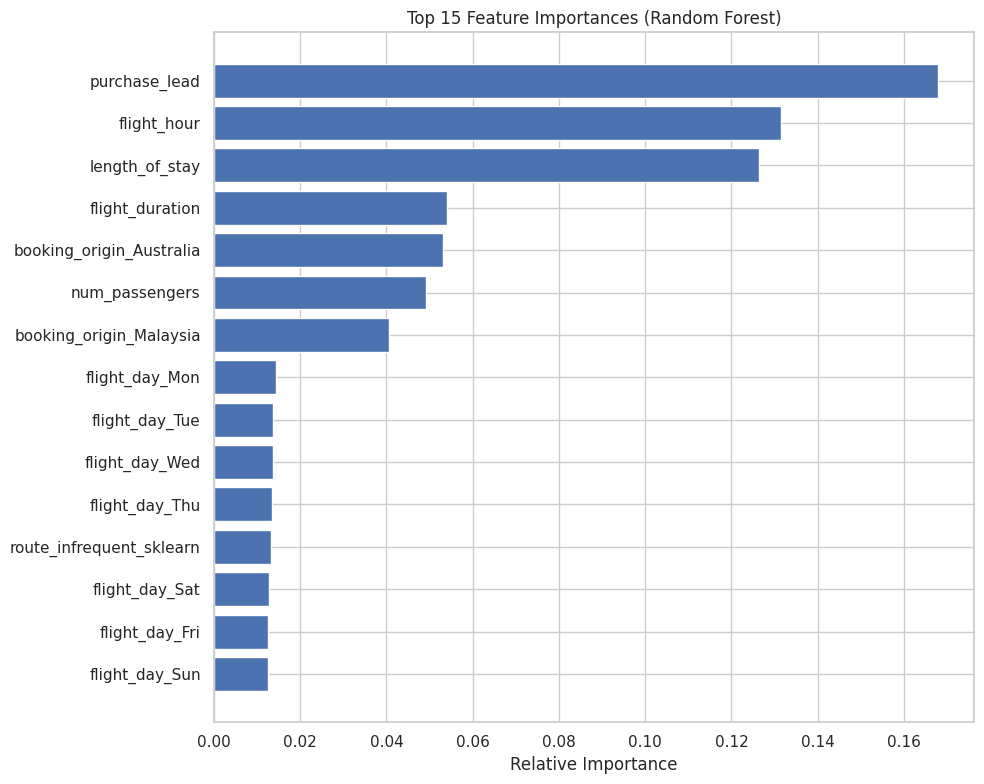

In [19]:
# Extract and visualize Random Forest feature importances
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Sort in descending order
indices = np.argsort(importances)[::-1]
top_n = 15

plt.figure(figsize=(10, 8))
plt.title(f'Top {top_n} Feature Importances (Random Forest)')
plt.barh(range(top_n), importances[indices[:top_n]][::-1], align='center')
plt.yticks(range(top_n), [feature_names[i] for i in indices[:top_n]][::-1])
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

In [20]:
# Select the decision threshold on validation data, then evaluate once on the held-out test set.
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import numpy as np

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Train a temporary model on the training portion and tune threshold on validation.
rf_subset = RandomForestClassifier(
    class_weight="balanced", n_estimators=100,
    random_state=42, n_jobs=-1
)
rf_subset.fit(X_tr, y_tr)
val_rf_probs = rf_subset.predict_proba(X_val)[:, 1]

prec_val, rec_val, thresh_val = precision_recall_curve(y_val, val_rf_probs)
f1_val = np.array([
    f1_score(y_val, (val_rf_probs >= threshold).astype(int), zero_division=0)
    for threshold in thresh_val
])
best_val_idx = int(np.argmax(f1_val))
best_val_threshold = float(thresh_val[best_val_idx])

print(f"Validation-selected threshold: {best_val_threshold:.4f}")
print(f"Validation F1 at selected threshold: {f1_val[best_val_idx]:.4f}")

# rf_model was fitted on the full training set in Cell 16.
# Evaluate it on the untouched test set using the validation-selected threshold.
final_test_probs = rf_model.predict_proba(X_test)[:, 1]
final_preds = (final_test_probs >= best_val_threshold).astype(int)

print("\n=== Final held-out test evaluation: Random Forest ===")
print(classification_report(y_test, final_preds, zero_division=0))


Validation-selected threshold: 0.1900
Validation F1 at selected threshold: 0.4137

=== Final held-out test evaluation: Random Forest ===
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      8379
           1       0.29      0.60      0.39      1478

    accuracy                           0.72      9857
   macro avg       0.60      0.67      0.60      9857
weighted avg       0.82      0.72      0.75      9857



In [21]:
# 5-fold stratified cross-validation on TRAINING DATA ONLY.
# The held-out test set is not used for model selection or cross-validation.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

print("=== 5-Fold Stratified Cross-Validation (training set only) ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro"
}

rf_cv = cross_validate(
    RandomForestClassifier(
        class_weight="balanced", n_estimators=100,
        random_state=42, n_jobs=-1
    ),
    X_train, y_train,
    cv=skf, scoring=scoring, n_jobs=-1
)

print(f"Mean ROC-AUC: {rf_cv['test_roc_auc'].mean():.4f} "
      f"(+/- {rf_cv['test_roc_auc'].std():.4f})")
print(f"Mean Macro F1: {rf_cv['test_f1_macro'].mean():.4f} "
      f"(+/- {rf_cv['test_f1_macro'].std():.4f})")


=== 5-Fold Stratified Cross-Validation (training set only) ===
Mean ROC-AUC: 0.7572 (+/- 0.0030)
Mean Macro F1: 0.5527 (+/- 0.0068)


In [22]:
# Precision-Recall Curve Comparison at 50%, 60%, 70%, and 80% recall ---
lr_precisions, lr_recalls, _ = precision_recall_curve(y_test, lr_probs)
rf_precisions, rf_recalls, _ = precision_recall_curve(y_test, rf_probs)

target_recalls = [0.5, 0.6, 0.7, 0.8]
print("=== Precision Comparison at Fixed Recall Targets ===")
for tr in target_recalls:
    # Find the precision corresponding to the recall closest to target
    lr_idx = np.argmin(np.abs(lr_recalls - tr))
    rf_idx = np.argmin(np.abs(rf_recalls - tr))
    print(f"At Recall {int(tr*100)}% -> Logistic Regression Precision: {lr_precisions[lr_idx]*100:.2f}%, Random Forest Precision: {rf_precisions[rf_idx]*100:.2f}%")

=== Precision Comparison at Fixed Recall Targets ===
At Recall 50% -> Logistic Regression Precision: 32.67%, Random Forest Precision: 30.72%
At Recall 60% -> Logistic Regression Precision: 31.06%, Random Forest Precision: 29.04%
At Recall 70% -> Logistic Regression Precision: 30.05%, Random Forest Precision: 27.54%
At Recall 80% -> Logistic Regression Precision: 26.65%, Random Forest Precision: 25.43%


In [23]:
# Install SHAP library for explainability
!pip install shap

In [ ]:
import shap

# Use ONE fixed sample for both calculating and plotting SHAP values.
X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_sample)

# SHAP output format differs across versions; handle common binary-class formats.
if isinstance(shap_values, list):
    positive_class_shap = shap_values[1]
elif getattr(shap_values, "ndim", 0) == 3:
    positive_class_shap = shap_values[:, :, 1]
else:
    positive_class_shap = shap_values

shap.summary_plot(positive_class_shap, X_sample)


In [ ]:
### Key Interpretations and Findings from the Analysis

- **Dataset & Class Imbalance**:
  - The dataset contains **49,281 unique records** after removing **719 duplicates**.
  - There is a highly imbalanced target variable (`booking_complete`): only **15.0%** of bookings are completed successfully, while **85.0%** are incomplete.

- **Impact of Customer Choice Add-ons (Upgrades)**:
  - **Extra Baggage**: Customers who request extra baggage have a completed booking rate of **16.72%**, compared to only **11.53%** for those who do not.
  - **Preferred Seats**: Selecting preferred seating increases the completion rate to **17.76%** (compared to **13.84%** without).
  - **In-flight Meals**: Requesting in-flight meals yields a slight improvement in the completed booking rate of **16.09%** (versus **14.18%** without).
  - *Insight*: Offering or prompting users to choose extra baggage and preferred seats during the workflow is positively associated with higher booking completion.

- **Predictive Model Performance**:
  - **Logistic Regression (Baseline)**: Achieved a **ROC-AUC of 0.7636**. Using balanced class weights, it shows strong recall for successful bookings (**74%**), but low precision (**29%**).
  - **Random Forest**: Achieved a **ROC-AUC of 0.7482** with default threshold. To balance precision and recall, threshold tuning on validation data identified **0.19** as the optimal cutoff. Under this threshold, the held-out test evaluation yielded **60% recall** and **29% precision** (F1-score: **0.39**).

- **Feature Importance & Key Drivers**:
  - The top features determining whether a customer completes a booking are **purchase_lead** (how early they search/book), **length_of_stay**, **flight_hour**, and **flight_duration**.
  - Categorical factors such as booking channels and booking origins (specifically country of origin/destinations) also display significant variance in completion rates.